In [ ]:
train = pd.read_csv("gabungannya_train_lr.csv")
valid = pd.read_csv("gabungannya_valid_lr.csv")
test = pd.read_csv("gabungannya_test_lr.csv")

# Grup jadi sequence per ecg

In [3]:
def build_dataset(df):
    grouped = df.groupby("ecg_id")

    X = []
    y = []

    for _, group in grouped:
        signal = group[[f'channel-{i}' for i in range(12)]].values
        label = group[['NORM','MI','STTC','HYP','CD']].iloc[0].values

        X.append(signal)
        y.append(label)

    return np.array(X), np.array(y)

In [86]:
X_train, y_train = build_dataset(train)
X_val, y_val = build_dataset(valid)
X_test, y_test = build_dataset(test)

In [87]:
X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape

((17418, 1000, 12),
 (2198, 1000, 12),
 (2198, 1000, 12),
 (17418, 5),
 (2198, 5),
 (2198, 5))

## padding 

In [6]:
lengths = [len(x) for x in X_train]

In [7]:
np.percentile(lengths, 95)

np.float64(1000.0)

In [8]:
MAX_LEN = 1000 

def pad_signal(x):
    if len(x) > MAX_LEN:
        return x[:MAX_LEN]
    else:
        pad = np.zeros((MAX_LEN - len(x), x.shape[1]))
        return np.vstack([x, pad])

In [9]:
X_train = np.array([pad_signal(x) for x in X_train])

# Ubah ke pytorch (dari (n_samples, seq_len, n_channels) jadi (batch, channel, seq_len))

In [88]:
X_train = np.transpose(X_train, (0, 2, 1))
X_val   = np.transpose(X_val, (0, 2, 1))
X_test  = np.transpose(X_test, (0, 2, 1))

# Dataset dan Dataloader

In [89]:
import torch
from torch.utils.data import DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [90]:
class ECGDataset(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [91]:
# setelah transpose
train_dataset = ECGDataset(X_train, y_train)
val_dataset   = ECGDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32)

In [92]:
X_val.shape

(2198, 12, 1000)

# Model resnet 1.0

In [57]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [58]:
class SimpleResNet1D(nn.Module):
    def __init__(self, n_classes=5):
        super().__init__()

        self.conv1 = nn.Conv1d(12, 64, kernel_size=7, padding=3)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv1d(64, 128, kernel_size=5, padding=2)
        self.bn2 = nn.BatchNorm1d(128)

        self.pool = nn.AdaptiveAvgPool1d(1)

        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))

        x = self.pool(x).squeeze(-1)

        out = torch.sigmoid(self.fc(x))
        return out

In [93]:
# ===== Residual Block 1D =====
class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock1D, self).__init__()
        
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3, 
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, 
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        
        self.downsample = downsample

    def forward(self, x):
        identity = x
        
        out = self.conv1(x)
        out = self.bn1(out)
        out = F.relu(out)
        
        out = self.conv2(out)
        out = self.bn2(out)
        
        if self.downsample is not None:
            identity = self.downsample(x)
        
        out += identity
        out = F.relu(out)
        
        return out


# ===== ResNet1D =====
class ResNet1D(nn.Module):
    def __init__(self, block, layers, in_channels=12, num_classes=5):
        super(ResNet1D, self).__init__()
        
        self.in_channels = 64
        
        # Initial layer
        self.conv1 = nn.Conv1d(in_channels, 64, kernel_size=7, 
                               stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU()
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        
        # ResNet layers
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        
        # Output
        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, block, out_channels, blocks, stride=1):
        downsample = None
        
        if stride != 1 or self.in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv1d(self.in_channels, out_channels, kernel_size=1, 
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )
        
        layers = []
        layers.append(block(self.in_channels, out_channels, stride, downsample))
        
        self.in_channels = out_channels
        
        for _ in range(1, blocks):
            layers.append(block(self.in_channels, out_channels))
        
        return nn.Sequential(*layers)

    def forward(self, x):
        # x: (batch, channels, sequence_length)
        
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        
        x = self.global_pool(x)   # (batch, 512, 1)
        x = x.squeeze(-1)         # (batch, 512)
        
        x = self.fc(x)
        
        return x

In [94]:
# ===== Helper function (mirip ResNet50 structure) =====
def resnet1d18(in_channels=12, num_classes=5):
    return ResNet1D(ResidualBlock1D, [2, 2, 2, 2], in_channels, num_classes)

# Setup train

In [61]:
from torch import optim
from tqdm.auto import tqdm
from jcopdl.callback import Callback

In [103]:
# model = SimpleResNet1D().to(device)
model = resnet1d18().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.000001)
callback = Callback(model)

### LOOP FN

In [99]:
def loop_fn(mode, dataset, dataloader, model, criterion, optimizer, device):
    if mode == "train":
        model.train()
    elif mode == "test":
        model.eval()

    cost = 0
    for feature, target in tqdm(dataloader, desc=mode.title()):
        feature, target = feature.to(device), target.to(device)
        output = model(feature)
        loss = criterion(output, target)

        if mode == "train":
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        cost += loss.item() * feature.shape[0]
    cost = cost / len(dataset)
    return cost

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     1
Train_cost  = 0.5923 | Test_cost  = 0.5552 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     2
Train_cost  = 0.5250 | Test_cost  = 0.4941 | 


... (50 outputs left out)


Epoch    19
Train_cost  = 0.3125 | Test_cost  = 0.3340 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    20
Train_cost  = 0.3108 | Test_cost  = 0.3362 | 


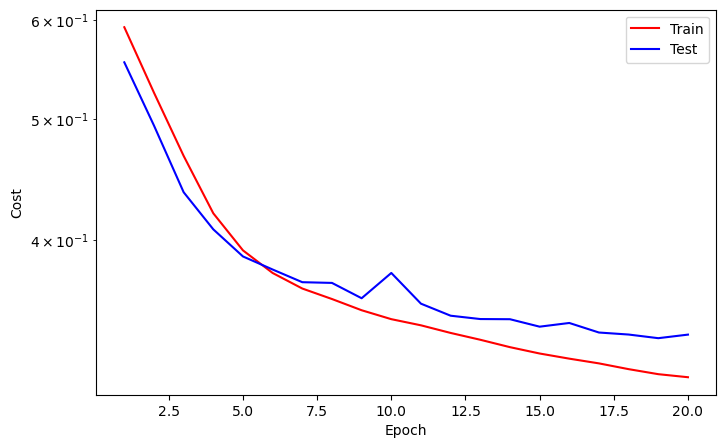

==> EarlyStop patience =  1 | Best test_cost: 0.3340


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    21
Train_cost  = 0.3080 | Test_cost  = 0.3332 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]

... (51 outputs left out)


Epoch    39
Train_cost  = 0.2773 | Test_cost  = 0.3278 | 
==> EarlyStop patience =  1 | Best test_cost: 0.3235


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    40
Train_cost  = 0.2763 | Test_cost  = 0.3222 | 


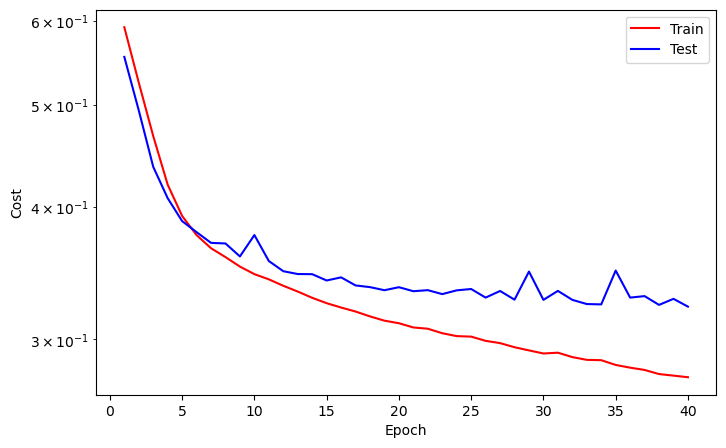

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    41
Train_cost  = 0.2746 | Test_cost  = 0.3263 | 
==> EarlyStop patience =  1 | Best test_cost: 0.3222


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    42
Train_cost  = 0.2736 | Test_cost  = 0.3204 | 


... (11 outputs left out)


Epoch    46
Train_cost  = 0.2665 | Test_cost  = 0.3230 | 
==> EarlyStop patience =  4 | Best test_cost: 0.3204


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    47
Train_cost  = 0.2656 | Test_cost  = 0.3261 | 
==> EarlyStop patience =  5 | Best test_cost: 0.3204
==> Execute Early Stopping at epoch: 47 | Best test_cost: 0.3204
==> Best model is saved at model


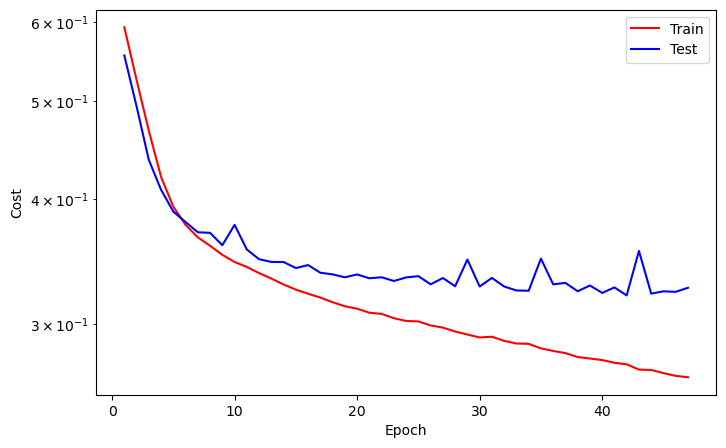

In [104]:
while True:
    train_cost = loop_fn("train", train_dataset, train_loader, model, criterion, optimizer, device)
    with torch.no_grad():
        test_cost = loop_fn("test", val_dataset, val_loader, model, criterion, optimizer, device)

    callback.log(train_cost, test_cost)
    callback.save_checkpoint()
    callback.cost_runtime_plotting()
    if callback.early_stopping(model, monitor='test_cost'):
        callback.plot_cost()
        break

### LOOP CGT

In [47]:
for epoch in range(10):
    model.train()

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()

        preds = model(X_batch)
        loss = criterion(preds, y_batch)

        loss.backward()
        optimizer.step()

In [48]:
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        preds = model(X_batch)

        all_preds.append(preds.cpu().numpy())
        all_targets.append(y_batch.numpy())

### AUROC

In [75]:
probs = np.vstack(all_preds)

threshold = 0.5
y_pred = (probs > threshold).astype(int)

In [76]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score

def evaluate_model(model, dataloader, device, threshold=0.5):
    model.eval()
    
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)

            probs = model(X_batch)  # output sigmoid (0-1)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(y_batch.numpy())

    # gabungkan semua batch
    probs = np.vstack(all_probs)
    targets = np.vstack(all_targets)

    # thresholding → jadi prediksi 0/1
    y_pred = (probs > threshold).astype(int)

    # =====================
    # F1 Score
    # =====================
    f1_micro = f1_score(targets, y_pred, average='micro')
    f1_macro = f1_score(targets, y_pred, average='macro')

    # =====================
    # AUROC
    # =====================
    try:
        auc_macro = roc_auc_score(targets, probs, average='macro')
    except:
        auc_macro = None  # kalau ada label yang tidak muncul

    return {
        "f1_micro": f1_micro,
        "f1_macro": f1_macro,
        "auc_macro": auc_macro
    }

In [77]:
metrics = evaluate_model(model, val_loader, device)

print(metrics)

{'f1_micro': 0.7427665477606025, 'f1_macro': 0.6796573984850152, 'auc_macro': 0.9205742431019879}


### Predict

In [ ]:
feature, target = next(iter(val_loader))
feature, target = feature.to(device), target.to(device)

In [ ]:
with torch.no_grad():
    model.eval()
    output = model(feature)
    preds = (output > 0.5).to(torch.float32)
preds

### CHTGPT

In [44]:
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for feature, target in val_loader:
        feature = feature.to(device)

        output = model(feature)
        preds = (output > 0.5).float()

        all_preds.append(preds.cpu())
        all_targets.append(target)

# gabungkan
all_preds = torch.cat(all_preds).numpy()
all_targets = torch.cat(all_targets).numpy()

In [45]:
from sklearn.metrics import f1_score

f1_micro = f1_score(all_targets, all_preds, average='micro')
f1_macro = f1_score(all_targets, all_preds, average='macro')

print("F1 Micro:", f1_micro)
print("F1 Macro:", f1_macro)

F1 Micro: 0.500245941957698
F1 Macro: 0.2986772008999874


In [46]:
from sklearn.metrics import roc_auc_score

# gunakan probabilitas, bukan preds
all_probs = []

with torch.no_grad():
    for feature, target in val_loader:
        feature = feature.to(device)

        output = model(feature)
        probs = output  # kalau pakai sigmoid

        all_probs.append(probs.cpu())

all_probs = torch.cat(all_probs).numpy()

auc = roc_auc_score(all_targets, all_probs, average='macro')
print("AUROC:", auc)

AUROC: 0.6406990970629085


### By YAYAT
